# Video Analysis: Shots, Scenes and Face Groups

This notebook analyses one YouTube video and produces the assignment deliverables:

| Output | How it is produced |
|---|---|
| **Shots** | Camera cuts detected locally with PySceneDetect |
| **Scenes** with descriptions | Consecutive shots grouped and described by a vision-language model on OpenRouter, using sampled frames and a local Whisper transcript |
| **Face groups** | Faces detected locally with InsightFace and clustered by embedding similarity |

Results are written to `outputs/analysis.json` and `outputs/extracted_faces/scene_NNN/group_NNN/`. The design is explained in `README.md`.

> Face groups are anonymous similarity clusters, not verified identities, and scene boundaries and descriptions are model output. Review both before relying on them.

## 1. Install dependencies

Run once per environment (Python 3.11 or newer), then restart the kernel. The first pipeline run also downloads the InsightFace and Whisper model weights.

In [1]:
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
%pip install -q -e "{ROOT}"

Note: you may need to restart the kernel to use updated packages.


## 2. Configure

Secrets come from a `.env` file in the project root (copy `.env.example`): `OPENROUTER_API_KEY` and, optionally, `OPENROUTER_MODEL`. Place the downloaded video at `VIDEO_PATH` and set its YouTube link below.

In [1]:
import json
import os
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

from video_analysis.evaluation import boundary_metrics, grouping_metrics
from video_analysis.faces import FaceGrouper
from video_analysis.media import probe
from video_analysis.pipeline import run_analysis
from video_analysis.scenes import SemanticAnalyzer
from video_analysis.schema import strict_json_loads

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
load_dotenv(ROOT / ".env", override=True)

VIDEO_PATH = ROOT / "data" / "input" / "episode.mp4"
YOUTUBE_URL = "https://www.youtube.com/watch?v=7uM4rcXXyiM&list=PLWCymGfobuvg"
OUTPUT_DIR = ROOT / "outputs"
CACHE_DIR = ROOT / "cache"

OPENROUTER_MODEL = os.environ.get("OPENROUTER_MODEL", "openrouter/free")
SAMPLE_FPS = 2.0         # frames sampled per second of each shot
WHISPER_MODEL = "small"  # faster-whisper model size
FACE_SIMILARITY = 0.48   # cosine similarity a face needs to join an existing group
MAX_API_REQUESTS = 100   # hard cap on OpenRouter calls, retries included

print(f"Python {sys.version.split()[0]} | {VIDEO_PATH.name} | {OPENROUTER_MODEL}")

objc[26659]: Class AVFFrameReceiver is implemented in both /Users/dharmikgovani/Documents/AAI/SceneGraphAI/SceneGraphAI/.venv/lib/python3.14/site-packages/cv2/.dylibs/libavdevice.63.1.102.dylib (0x114eb0328) and /Users/dharmikgovani/Documents/AAI/SceneGraphAI/SceneGraphAI/.venv/lib/python3.14/site-packages/av/.dylibs/libavdevice.62.3.103.dylib (0x1151603a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[26659]: Class AVFAudioReceiver is implemented in both /Users/dharmikgovani/Documents/AAI/SceneGraphAI/SceneGraphAI/.venv/lib/python3.14/site-packages/cv2/.dylibs/libavdevice.63.1.102.dylib (0x114eb0378) and /Users/dharmikgovani/Documents/AAI/SceneGraphAI/SceneGraphAI/.venv/lib/python3.14/site-packages/av/.dylibs/libavdevice.62.3.103.dylib (0x1151603f8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
/Users/dharmikgovani/Documents/AAI/SceneGraphAI/

Python 3.14.7 | episode.mp4 | openrouter/free


## 3. Inspect the input

In [2]:
video = probe(VIDEO_PATH)
print(f"{video.filename}: {video.duration_s / 60:.1f} min, {video.width}x{video.height}, "
      f"sha256 {video.sha256[:12]}")

episode.mp4: 4.4 min, 638x360, sha256 321eb7646eab


## 4. Load the face model and check the LLM

The preflight sends a tiny green image to the configured OpenRouter model and expects `{"color": "green"}` back as strict JSON, so a model without image or structured-output support fails here in seconds instead of halfway through the run.

In [3]:
face_grouper = FaceGrouper(similarity_threshold=FACE_SIMILARITY)
face_grouper.load_model()

semantic_analyzer = SemanticAnalyzer(OPENROUTER_MODEL, CACHE_DIR / "semantic", max_requests=MAX_API_REQUESTS)
semantic_analyzer.preflight()
print("Face model loaded; the LLM accepts images and returns strict JSON.")

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /Users/dharmikgovani/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /Users/dharmikgovani/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /Users/dharmikgovani/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /Users/dharmikgovani/.insightface/models/buffalo_l/genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /Users/dharmikgovani/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)
Face model loaded; 

## 5. Run the pipeline

```mermaid
flowchart LR
  V[Video file] --> S[Shot detection]
  V --> T[Whisper transcript]
  S --> F[Frame sampling]
  F --> G[Face detection and grouping]
  S & T & F & G --> B[LLM: scene boundaries]
  B --> D[LLM: scene descriptions]
  D --> C[Validation]
  C --> O[analysis.json and extracted_faces/]
```

Each stage is cached in `cache/`, keyed by the video's hash and the settings it depends on, and every accepted LLM answer is cached too. Re-running is therefore cheap, and a run interrupted by a rate limit resumes where it stopped. Every model call is logged, without content or keys, to `cache/semantic/llm-traces.jsonl`.

In [4]:
analysis = run_analysis(VIDEO_PATH, YOUTUBE_URL, OUTPUT_DIR, CACHE_DIR, face_grouper, semantic_analyzer,
                        sample_fps=SAMPLE_FPS, whisper_model=WHISPER_MODEL)

group_count = len({face.group_id for face in analysis.faces})
print(f"{len(analysis.shots)} shots, {len(analysis.scenes)} scenes, {len(analysis.transcript)} transcript segments, "
      f"{len(analysis.faces)} faces in {group_count} groups")
print(f"OpenRouter requests: {semantic_analyzer.requests_made}, cached answers reused: {semantic_analyzer.cache_hits}")

81 shots, 14 scenes, 50 transcript segments, 653 faces in 42 groups
OpenRouter requests: 3, cached answers reused: 24


## 6. Review the scenes

`review` marks scenes where the model reported uncertainty about the description or the boundary that opens the scene.

,scene,start_s,end_s,shots,kind,face_groups,review,description
0,0,0.0,1.2,1,story,,False,"The scene consists entirely of a black screen with no visible imagery, characters, or action. This darkness persists throughout the short duration of the shot."
1,1,1.2,5.3,1,montage,"group_001, group_002",False,"A young woman and a young man sit side-by-side on a black leather couch in a living room, with wooden shelves filled with framed photos and objects behind them. The text 'the year 2030' appears on the screen as they look forward."
2,2,5.3,7.3,2,montage,"group_003, group_004",False,"A blonde woman in a purple dress smiles while holding a cocktail glass, engaging with a man in a grey suit who holds a drink in return. The man, wearing a tie, smiles back at her across the table. The transcript indicates this moment corresponds to 2012 when Barney met a girl named Quinn."
3,3,7.3,9.3,1,story,group_005,True,"A man in a gray cardigan sits facing a woman with brown shoulder-length hair and a pink top whose back is to the camera; their hands are clasped on the table between them and his expression is serious and downcast. The shot holds on the pair in a quiet, somber beat as a voice-over recap mentions Barney meeting a girl named Quinn and Kevin un-proposing to Robin."
4,4,9.3,12.8,3,montage,"group_006, group_007",False,"At night on an outdoor patio illuminated by string lights with a city skyline in the background, a man in a sweater stands facing a woman in a black coat. He confesses his love for her, addressing her by name, and then mentions asking if she loved him back. The camera cuts between a wide shot of the pair and close-ups of their faces during the conversation."
5,5,12.8,16.4,2,story,"group_006, group_007",False,"In an apartment living room, a dark-haired man in a dark striped sweater sits on a couch speaking earnestly to a woman with shoulder-length brown hair wearing a tan blazer (frame_000026–frame_000029, shot_0009). The camera cuts to a reverse angle of the woman, who listens with a pained, concerned expression (frame_000030–frame_000033, shot_0010). The subtitles show a serious personal exchange: one line recalls asking 'if she loved me back,' and the next reports that 'Marshall told Robin, ""You gotta move out""' (text_0003, text_0004), indicating a weighty relationship conversation."
6,6,16.4,32.4,5,story,"group_006, group_008, group_009",True,"In a red-walled bedroom, a man in a dark cardigan faces a woman with dark curly hair as he relays that Marshall told Robin she has to move out and can no longer even open her bedroom door. A man in a striped sweater then steps through a doorway into the red-carpeted room past a window with drawn blinds. The segment closes on two men seated at a bar with drinks, one in a light blue shirt turning toward the other."
7,7,32.4,118.4,26,story,"group_004, group_006, group_010, group_011, group_012, group_013, group_014, group_015, group_016, group_017, group_018, group_019, group_020",False,"Two men at a bar table carry on a continuous conversation: a man in a grey suit and dark tie, holding a drink, talks with a friend in a light blue shirt who gestures while seated beside him (frame_000096, frame_000143, frame_000220, frame_000236). The friend ribs him about being a sensitive, 'gooey romantic' over a woman named Quinn, and the suited man protests that his feelings are real while vividly recalling her (text_0006, text_0007, text_0011, text_0012, text_0013). He laments that he cannot reach her and that he keeps imagining he sees her everywhere, including dancing on a pole, prompting a surprised reaction (text_0020, text_0021, text_0022)."
8,8,118.4,122.8,1,montage,"group_021, group_022, group_023, group_024, group_025",False,"A woman with reddish hair holds a cell phone to her ear in a dimly lit environment. The scene transitions to a title card reading ""how i met your mother"" overlaid on a group of four people standing together. Audio transcript indicates a character expresses app

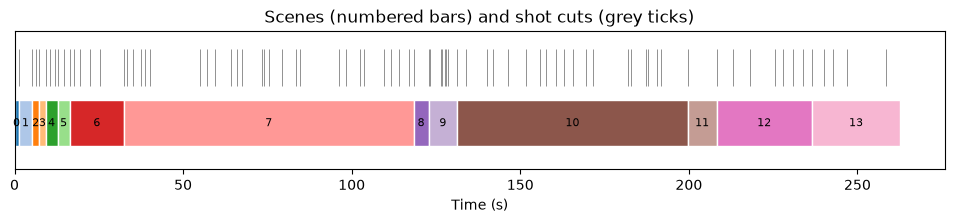

In [5]:
scene_table = pd.DataFrame([{
    "scene": number, "start_s": round(scene.start_s, 1), "end_s": round(scene.end_s, 1),
    "shots": len(scene.shot_ids), "kind": scene.kind, "face_groups": ", ".join(scene.face_group_ids),
    "review": scene.needs_review, "description": scene.description,
} for number, scene in enumerate(analysis.scenes)])
with pd.option_context("display.max_colwidth", None):
    display(scene_table)

fig, ax = plt.subplots(figsize=(12, 1.8))
for number, scene in enumerate(analysis.scenes):
    ax.barh(0, scene.end_s - scene.start_s, left=scene.start_s, height=0.5,
            color=plt.cm.tab20(number % 20), edgecolor="white")
    ax.text((scene.start_s + scene.end_s) / 2, 0, str(number), ha="center", va="center", fontsize=8)
for shot in analysis.shots[1:]:
    ax.vlines(shot.start_s, 0.4, 0.8, color="grey", linewidth=0.6)
ax.set(xlabel="Time (s)", ylim=(-0.5, 1), yticks=[], title="Scenes (numbered bars) and shot cuts (grey ticks)")
plt.show()

## 7. Review the face groups

Each row shows crops spread across one group, largest groups first. A row that mixes different people means the similarity threshold is too low; one person spread over several rows means it is too high.

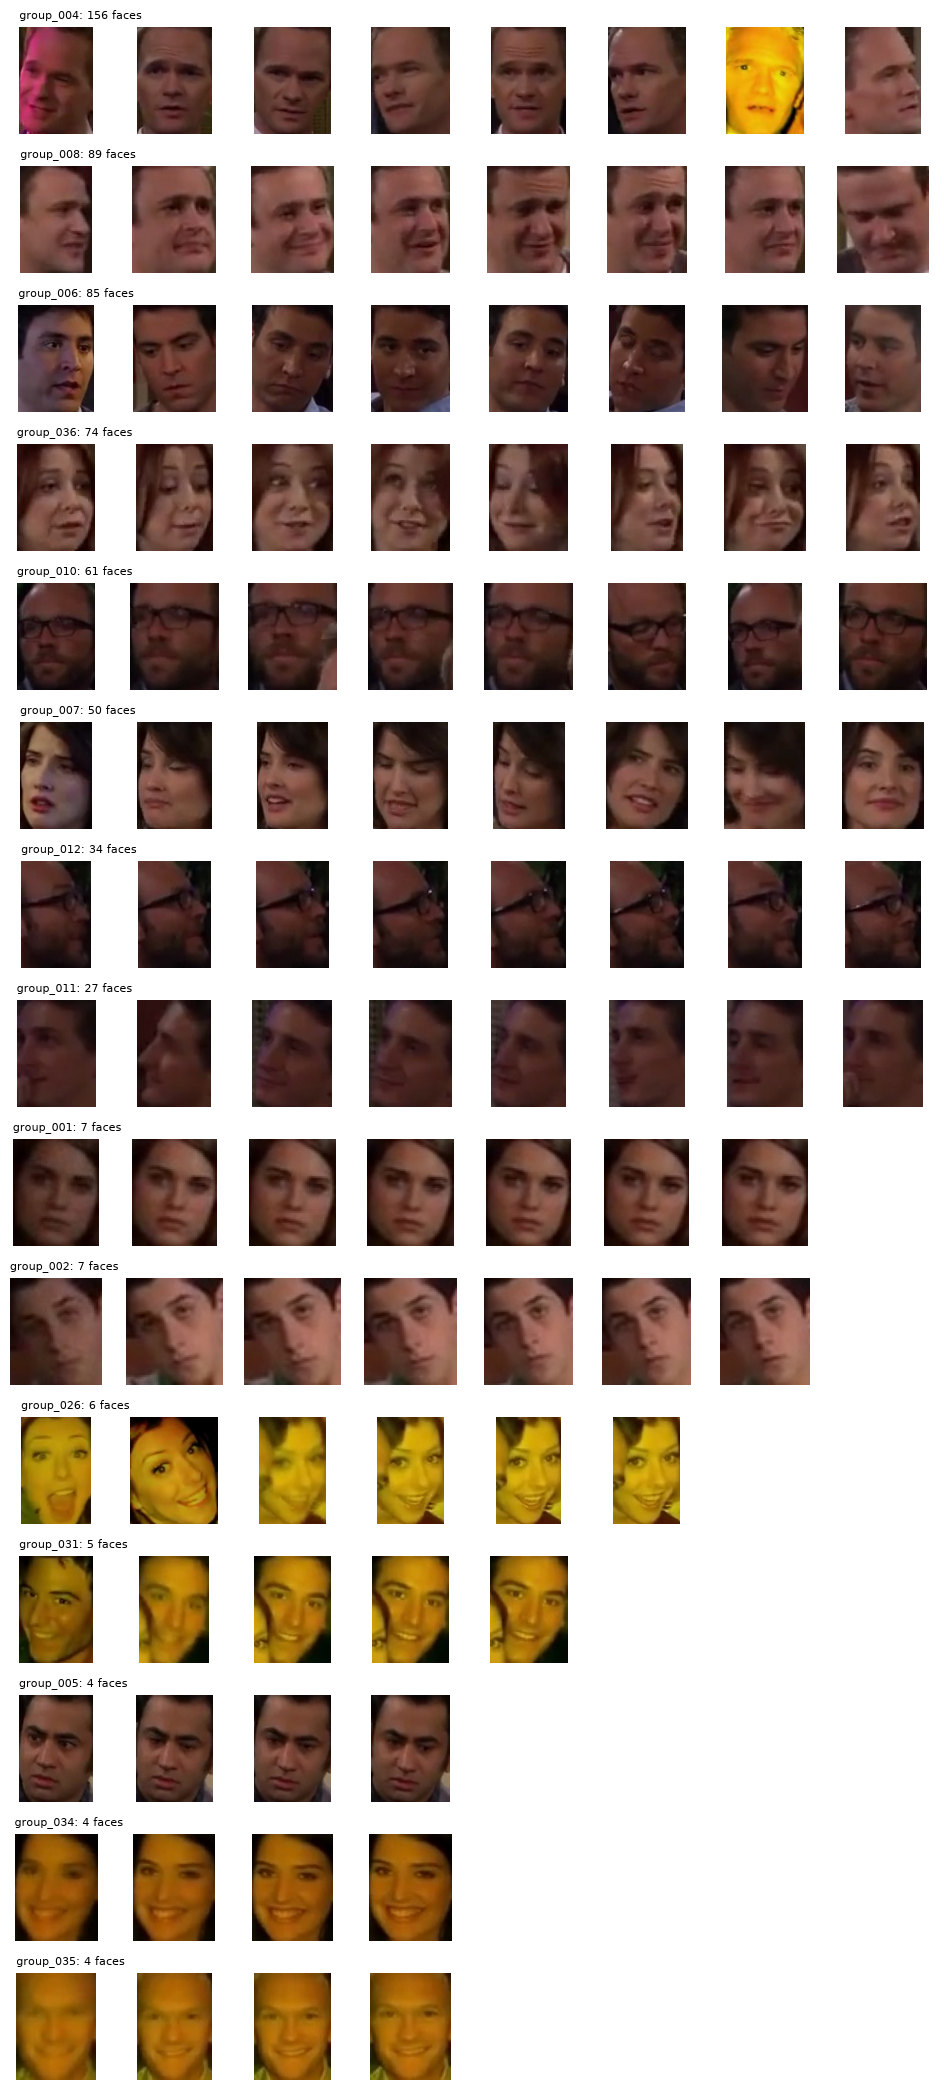

In [6]:
CROPS_PER_GROUP, MAX_GROUPS_SHOWN = 8, 15

crops_by_group = defaultdict(list)
for path in sorted((OUTPUT_DIR / "extracted_faces").glob("scene_*/group_*/*.jpg")):
    crops_by_group[path.parent.name].append(path)
groups = sorted(crops_by_group, key=lambda group: -len(crops_by_group[group]))[:MAX_GROUPS_SHOWN]

fig, axes = plt.subplots(len(groups), CROPS_PER_GROUP, squeeze=False,
                         figsize=(CROPS_PER_GROUP * 1.2, len(groups) * 1.4))
for row, group in zip(axes, groups):
    paths = crops_by_group[group]
    count = min(CROPS_PER_GROUP, len(paths))
    for axis in row:
        axis.axis("off")
    for axis, index in zip(row, range(count)):
        axis.imshow(plt.imread(paths[index * len(paths) // count]))
    row[0].set_title(f"{group}: {len(paths)} faces", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

## 8. Optional: measure accuracy

The pipeline's automatic checks prove the output is internally consistent, not that it is correct. To measure accuracy, label a sample by hand below and re-run the cell. Face crops are labelled by their path under `outputs/extracted_faces/`, which already contains the predicted group.

In [7]:
TRUE_CUTS_S = []          # times (s) of real camera cuts
TRUE_SCENE_STARTS_S = []  # times (s) where real scenes start, excluding 0
TRUE_PEOPLE = {}          # crop path -> person, e.g. {"scene_001/group_002/face_000_00-00-01.960.jpg": "woman_on_couch"}

if TRUE_CUTS_S:
    print("Shot cuts:", boundary_metrics([shot.start_s for shot in analysis.shots[1:]], TRUE_CUTS_S, tolerance_s=0.1))
if TRUE_SCENE_STARTS_S:
    print("Scene starts:", boundary_metrics([scene.start_s for scene in analysis.scenes[1:]],
                                              TRUE_SCENE_STARTS_S, tolerance_s=1.0))
if TRUE_PEOPLE:
    print("Face groups:", grouping_metrics(list(TRUE_PEOPLE.values()),
                                           [Path(path).parent.name for path in TRUE_PEOPLE]))
if not (TRUE_CUTS_S or TRUE_SCENE_STARTS_S or TRUE_PEOPLE):
    print("No manual labels provided; accuracy was not measured.")

No manual labels provided; accuracy was not measured.


## 9. Verify the submission files

Re-reads `analysis.json` from disk, checks it has exactly the required fields, and checks that every face group listed for a scene has its folder of crops.

In [8]:
submission = strict_json_loads((OUTPUT_DIR / "analysis.json").read_text())
assert list(submission) == ["video_url", "shots", "scenes"]
assert all(list(shot) == ["id", "start_seconds", "end_seconds"] for shot in submission["shots"])
assert all(list(scene) == ["id", "start_seconds", "end_seconds", "description", "faces"]
           for scene in submission["scenes"])
for scene in submission["scenes"]:
    for group_id, timecodes in scene["faces"].items():
        folder = OUTPUT_DIR / "extracted_faces" / f"scene_{scene['id']:03d}" / group_id
        assert len(list(folder.glob("*.jpg"))) >= len(timecodes), f"Missing crops in {folder}"

print(f"analysis.json is valid: {len(submission['shots'])} shots, {len(submission['scenes'])} scenes")
print(json.dumps(submission["scenes"][0], indent=2))

analysis.json is valid: 81 shots, 14 scenes
{
  "id": 0,
  "start_seconds": 0.0,
  "end_seconds": 1.21,
  "description": "The scene consists entirely of a black screen with no visible imagery, characters, or action. This darkness persists throughout the short duration of the shot.",
  "faces": {}
}


## Submission

- **Code**: `src/video_analysis/`, this notebook and `tests/`
- **Video link**: `YOUTUBE_URL` above, also stored in `analysis.json`
- **JSON**: `outputs/analysis.json`
- **Face folders**: `outputs/extracted_faces/scene_NNN/group_NNN/`

**Known limitations.** Face groups can split one person (profile vs. frontal, lighting) or merge look-alikes; faces are only found in sampled frames, so very brief appearances can be missed; scene boundaries and descriptions come from a model and can be wrong, especially for flashbacks and montages. The free OpenRouter route may pick a different underlying model per request, so descriptions can vary in style.